# 06 · Evaluación en test

Hasta ahora todos los resultados eran de validación cruzada sobre el train. En este notebook cogemos los seis modelos finales de los notebooks 04 y 05, los entrenamos con todo el train y los evaluamos **una sola vez** en el test (451 pacientes que no se han usado para nada).

Modelos:

- Modelos base: logística, logística con `class_weight` y árbol de decisión.
- Ensembles: Random Forest, Gradient Boosting y XGBoost.

Cada uno con su mejor configuración de preprocesamiento e hiperparámetros, que leemos de `results/mejores_modelos_base.csv` y `results/mejores_ensembles.csv`.

In [1]:
import ast
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (f1_score, recall_score, precision_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

sys.path.append(str(Path.cwd().parent))
from src.config import SEED, RESULTS_DIR, CLASS_NAMES
from src.validacion import (cargar_datos, dividir_train_test, entrenar_final, evaluar_en_test,
                            CLASE_ALTO, guardar_tabla)

## 1. Datos y modelos

Misma partición que en todos los notebooks. Los modelos se crean igual que en los notebooks 04 y 05 y se les ponen los mejores hiperparámetros.

In [2]:
X, y = cargar_datos()
X_train, X_test, y_train, y_test = dividir_train_test(X, y)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Pacientes de cada clase en test:", y_test.value_counts().sort_index().rename(CLASS_NAMES).to_dict())

Train: (1803, 27)  Test: (451, 27)
Pacientes de cada clase en test: {'Bajo': 226, 'Moderado': 135, 'Alto': 90}


In [3]:
MODELOS = {
    "logistica": LogisticRegression(max_iter=5000),
    "logistica_class_weight": LogisticRegression(max_iter=5000),
    "arbol": DecisionTreeClassifier(random_state=SEED),
    "random_forest": RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=1),
    "gradient_boosting": GradientBoostingClassifier(random_state=SEED),
    "xgboost": XGBClassifier(random_state=SEED, n_jobs=1, tree_method="hist", eval_metric="mlogloss"),
}

mejores = pd.concat([pd.read_csv(RESULTS_DIR / "mejores_modelos_base.csv"),
                     pd.read_csv(RESULTS_DIR / "mejores_ensembles.csv")], ignore_index=True)
# los hiperparámetros se guardaron como texto en el csv
mejores["mejores_parametros"] = mejores["mejores_parametros"].apply(ast.literal_eval)
mejores = mejores.set_index("modelo")
mejores[["imputacion", "escalado", "balanceo", "mejores_parametros", "f1_macro_media", "recall_alto_media"]]

,imputacion,escalado,balanceo,mejores_parametros,f1_macro_media,recall_alto_media
modelo,,,,,,
logistica,knn,yeojohnson,ninguno,{'C': 0.1},0.642563,0.661948
logistica_class_weight,knn,yeojohnson,class_weight,{'C': 1},0.638897,0.747907
arbol,knn,estandar,smotenc,"{'criterion': 'entropy', 'max_depth': 8, 'min_...",0.546312,0.612062
random_forest,mediana,estandar,class_weight,"{'max_depth': 10, 'max_features': 'sqrt', 'min...",0.635933,0.709056
gradient_boosting,mediana,estandar,class_weight,"{'subsample': 1.0, 'n_estimators': 400, 'min_s...",0.639149,0.689764
xgboost,mediana,estandar,ninguno,"{'subsample': 0.7, 'reg_lambda': 1, 'n_estimat...",0.651181,0.681469


## 2. Métricas en test

Usamos las mismas métricas que en la validación (F1 macro, balanced accuracy, recall de riesgo alto y accuracy) y añadimos el AUC macro (uno contra el resto), que mide si el modelo ordena bien a los pacientes por probabilidad sin depender del umbral.

Además contamos el error más grave: **pacientes de riesgo alto clasificados como riesgo bajo**. Esos pacientes se irían a casa sin seguimiento.

In [4]:
pipes, filas, matrices, informes = {}, [], {}, {}
for nombre, modelo in MODELOS.items():
    pipe = entrenar_final(modelo, mejores.loc[nombre], X_train, y_train)
    metricas, matriz, informe = evaluar_en_test(pipe, X_test, y_test)
    metricas["auc_macro"] = roc_auc_score(y_test, pipe.predict_proba(X_test), multi_class="ovr", average="macro")
    metricas["alto_como_bajo"] = matriz.loc["real Alto", "pred Bajo"]
    pipes[nombre], matrices[nombre], informes[nombre] = pipe, matriz, informe
    filas.append({"modelo": nombre, **metricas})

test = pd.DataFrame(filas).sort_values("f1_macro", ascending=False).reset_index(drop=True)
guardar_tabla(test, "evaluacion_test")
test.round(3)

,modelo,f1_macro,bal_acc,recall_alto,accuracy,auc_macro,alto_como_bajo
0,xgboost,0.715,0.716,0.722,0.741,0.869,3
1,logistica,0.697,0.696,0.700,0.729,0.861,5
2,logistica_class_weight,0.674,0.691,0.778,0.696,0.850,2
3,gradient_boosting,0.656,0.666,0.722,0.678,0.847,3
4,random_forest,0.644,0.651,0.689,0.683,0.853,2
5,arbol,0.530,0.545,0.622,0.557,0.749,12


- XGBoost queda primero en F1 macro (0,715) y en AUC (0,869), seguido de la logística (0,697 y 0,861). Los dos primeros son los mismos que en la validación cruzada.
- La logística con `class_weight` tiene un F1 macro algo más bajo (0,674), pero el mejor recall de riesgo alto (0,778) y la que menos pacientes de riesgo alto manda a riesgo bajo (2, igual que Random Forest).
- El árbol es el peor en todas las métricas y clasifica como riesgo bajo a 12 pacientes de riesgo alto.
- El AUC está entre 0,85 y 0,87 en todos menos en el árbol (0,75). Los modelos ordenan bien a los pacientes por riesgo; donde fallan es en el corte entre clases, sobre todo con la clase moderado.
- Todos los modelos salen algo mejor en test que en la validación cruzada. Lo vemos en el apartado 5.

## 3. Matrices de confusión

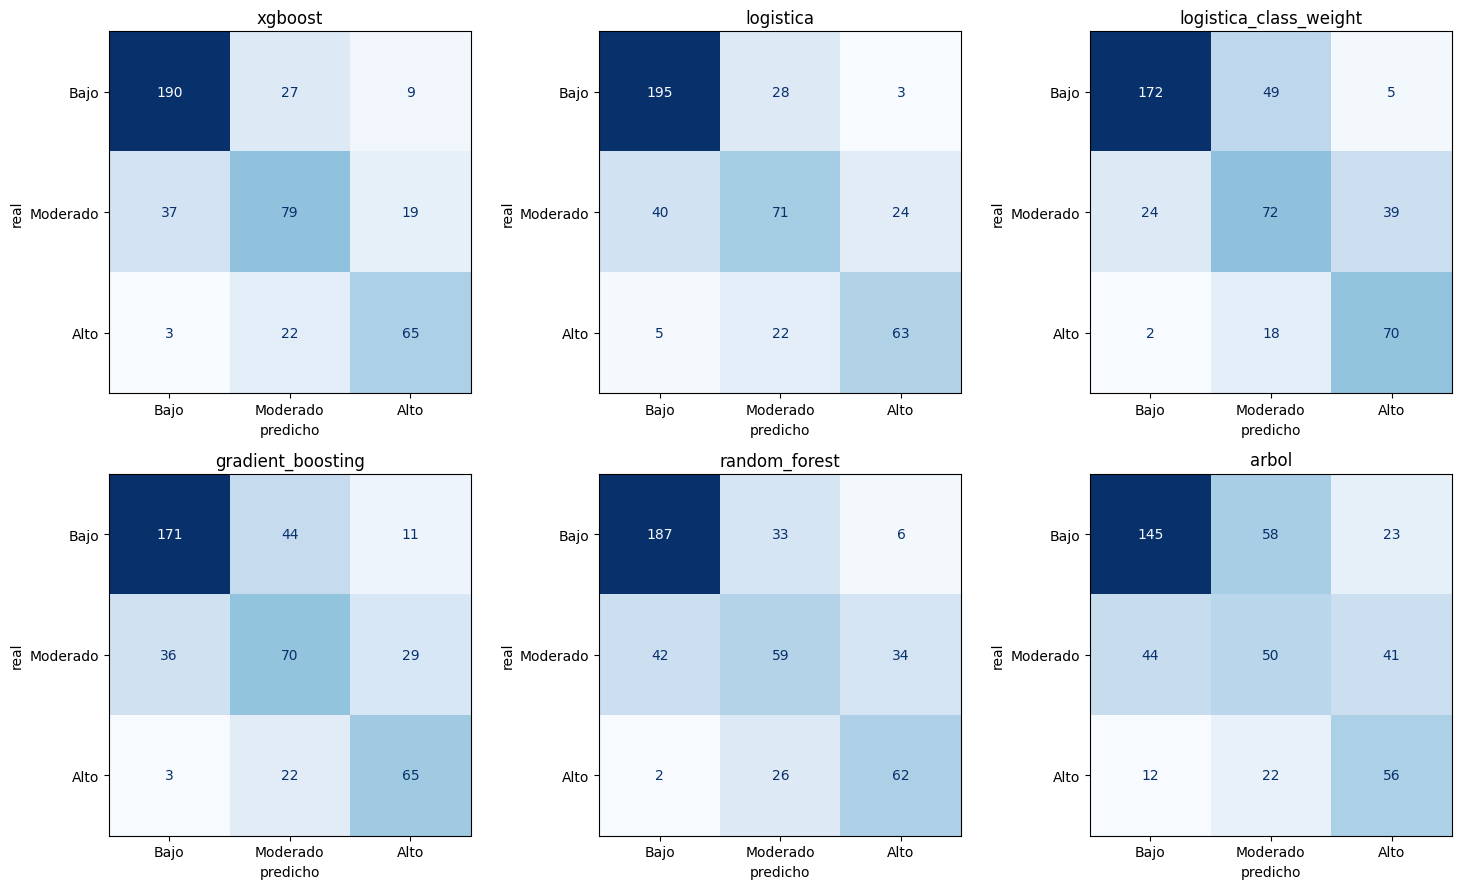

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
nombres_clase = [CLASS_NAMES[c] for c in sorted(CLASS_NAMES)]
for ax, nombre in zip(axes.ravel(), test.modelo):
    ConfusionMatrixDisplay(matrices[nombre].values, display_labels=nombres_clase).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre)
    ax.set_xlabel("predicho")
    ax.set_ylabel("real")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "evaluacion_matrices_confusion.png", dpi=150)
plt.show()

- En todos los modelos la clase moderado es la que peor se predice: de 135 pacientes, entre 50 y 79 bien. Se confunde con las dos de al lado, lo que tiene sentido porque es la clase intermedia.
- Los errores graves (alto como bajo y bajo como alto) son pocos, salvo en el árbol. Casi todos los pacientes de riesgo alto mal clasificados salen como moderado (entre 18 y 26), que al menos tendrían seguimiento.
- Se ve bien el efecto de `class_weight` en la logística: detecta 70 de los 90 pacientes de riesgo alto en vez de 63, pero a cambio marca como alto a 39 moderados (24 sin pesos) y acierta menos riesgos bajos (172 en vez de 195). Es el compromiso de siempre entre detectar más y dar más falsas alarmas.

### Métricas por clase

Precisión y recall de cada clase en test. La precisión de riesgo alto dice cuántos de los que el modelo marca como alto lo son de verdad (falsas alarmas), y el recall cuántos de los de riesgo alto detecta.

In [6]:
por_clase = []
for nombre, pipe in pipes.items():
    pred = pipe.predict(X_test)
    for c in sorted(CLASS_NAMES):
        por_clase.append({"modelo": nombre, "clase": CLASS_NAMES[c],
                          "precision": precision_score(y_test, pred, labels=[c], average="macro"),
                          "recall": recall_score(y_test, pred, labels=[c], average="macro"),
                          "f1": f1_score(y_test, pred, labels=[c], average="macro")})
por_clase = pd.DataFrame(por_clase)
guardar_tabla(por_clase, "evaluacion_por_clase")
por_clase.pivot(index="modelo", columns="clase", values=["recall", "precision"]).round(3).loc[test.modelo]

recall                 precision                
clase                    Alto   Bajo Moderado      Alto   Bajo Moderado
modelo                                                                 
xgboost                 0.722  0.841    0.585     0.699  0.826    0.617
logistica               0.700  0.863    0.526     0.700  0.812    0.587
logistica_class_weight  0.778  0.761    0.533     0.614  0.869    0.518
gradient_boosting       0.722  0.757    0.519     0.619  0.814    0.515
random_forest           0.689  0.827    0.437     0.608  0.810    0.500
arbol                   0.622  0.642    0.370     0.467  0.721    0.385

In [7]:
print(informes["logistica_class_weight"])

              precision    recall  f1-score   support

        Bajo      0.869     0.761     0.811       226
    Moderado      0.518     0.533     0.526       135
        Alto      0.614     0.778     0.686        90

    accuracy                          0.696       451
   macro avg      0.667     0.691     0.674       451
weighted avg      0.713     0.696     0.701       451



- El recall de riesgo bajo va de 0,64 a 0,86 y el de moderado se queda entre 0,37 y 0,59. Moderado es la clase difícil en todos los modelos.
- La precisión de riesgo alto es 0,70 en XGBoost y en la logística, y 0,61 en la logística con `class_weight`: de cada 10 pacientes que marca como alto, 6 lo son. En un contexto clínico una falsa alarma supone pruebas o seguimiento de más, que es mucho menos grave que no detectar a un paciente de riesgo alto.
- XGBoost es el que mejor predice la clase moderado (recall 0,585 y precisión 0,617), y por eso tiene el mejor F1 macro.

## 4. Incertidumbre del test

El test tiene 451 pacientes, y solo 90 de riesgo alto, así que cada paciente de riesgo alto mueve el recall en más de una centésima. Para ver cuánto nos podemos fiar de las diferencias, calculamos un intervalo de confianza del 95 % con bootstrap: remuestreamos los pacientes del test 1000 veces y recalculamos las métricas con las mismas predicciones.

In [8]:
rng = np.random.default_rng(SEED)
preds = {nombre: pipe.predict(X_test) for nombre, pipe in pipes.items()}
y_arr = y_test.to_numpy()
muestras = []
for b in range(1000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    for nombre, pred in preds.items():
        muestras.append({"modelo": nombre, "f1_macro": f1_score(y_arr[idx], pred[idx], average="macro"),
                         "recall_alto": recall_score(y_arr[idx], pred[idx], labels=[CLASE_ALTO], average="macro")})
muestras = pd.DataFrame(muestras)

intervalos = muestras.groupby("modelo").quantile([0.025, 0.975]).unstack().round(3)
intervalos.columns = [f"{m}_{'inf' if q < 0.5 else 'sup'}" for m, q in intervalos.columns]
intervalos = test.set_index("modelo")[["f1_macro", "recall_alto"]].round(3).join(intervalos)
guardar_tabla(intervalos.reset_index(), "evaluacion_test_intervalos")
intervalos

,f1_macro,recall_alto,f1_macro_inf,f1_macro_sup,recall_alto_inf,recall_alto_sup
modelo,,,,,,
xgboost,0.715,0.722,0.670,0.755,0.632,0.814
logistica,0.697,0.700,0.652,0.742,0.605,0.796
logistica_class_weight,0.674,0.778,0.627,0.716,0.687,0.856
gradient_boosting,0.656,0.722,0.607,0.697,0.629,0.815
random_forest,0.644,0.689,0.594,0.690,0.585,0.784
arbol,0.530,0.622,0.483,0.576,0.523,0.718


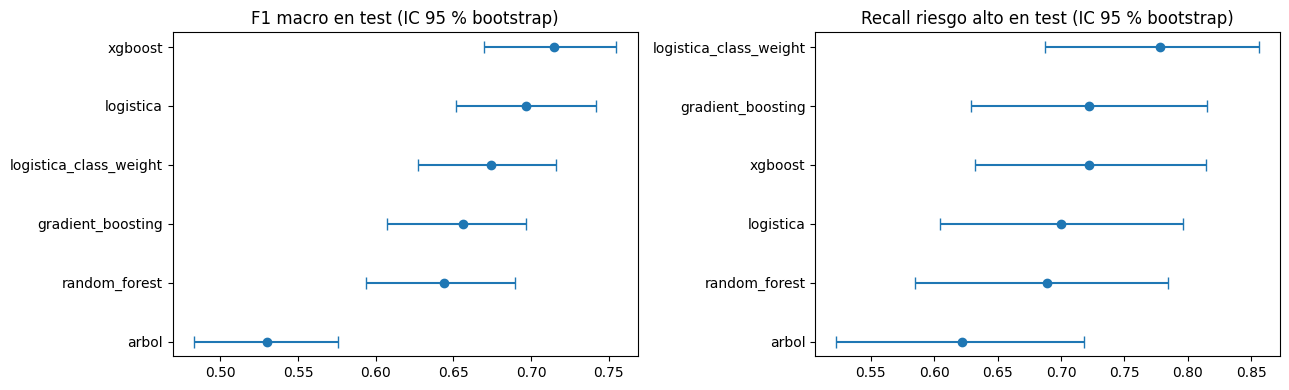

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, m, titulo in [(axes[0], "f1_macro", "F1 macro"), (axes[1], "recall_alto", "Recall riesgo alto")]:
    t = intervalos.sort_values(m)
    ax.errorbar(t[m], t.index, xerr=[t[m] - t[f"{m}_inf"], t[f"{m}_sup"] - t[m]], fmt="o", capsize=4)
    ax.set_title(f"{titulo} en test (IC 95 % bootstrap)")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "evaluacion_test_intervalos.png", dpi=150)
plt.show()

- Los intervalos son anchos: unas ±0,045 en F1 macro y unas ±0,09 en recall de riesgo alto. Es lo que da un test de 451 pacientes.
- Los intervalos de XGBoost, la logística y la logística con `class_weight` se solapan casi del todo. Con el test no podemos decir que XGBoost sea mejor que la logística. Lo único claro es que el árbol es peor que todos los demás: su intervalo de F1 macro no llega a tocar el de ningún otro modelo.
- Por eso la comparación estadística entre modelos la hacemos con las 15 particiones de la validación cruzada, en el notebook 07, y no con el test.

## 5. Validación cruzada frente a test

Comparamos el F1 macro y el recall de riesgo alto de la validación cruzada 5x3 con los del test. Si el esquema de validación está bien hecho, deberían parecerse.

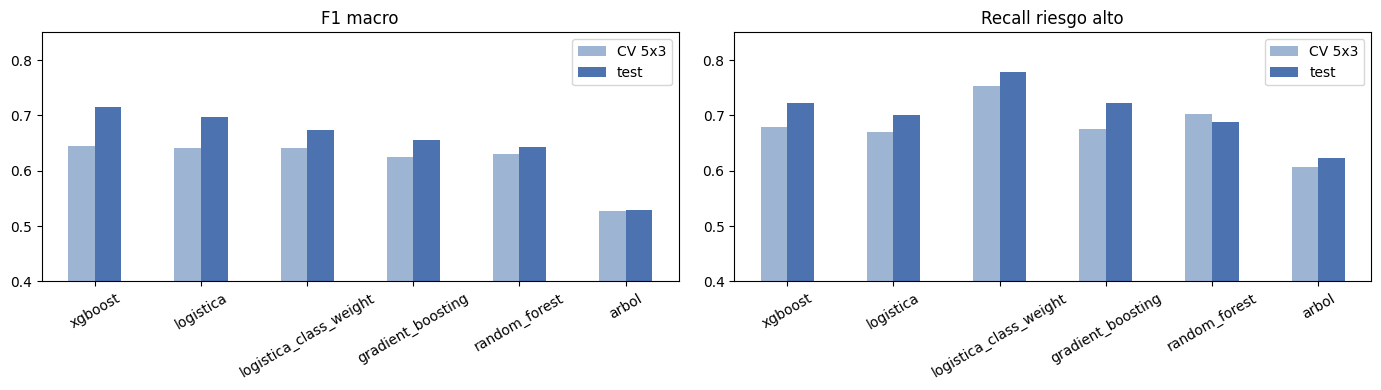

,f1_macro_cv,recall_alto_cv,f1_macro_test,recall_alto_test
modelo,,,,
xgboost,0.645,0.679,0.715,0.722
logistica,0.641,0.670,0.697,0.700
logistica_class_weight,0.640,0.753,0.674,0.778
gradient_boosting,0.625,0.676,0.656,0.722
random_forest,0.630,0.702,0.644,0.689
arbol,0.528,0.607,0.530,0.622


In [10]:
cv = pd.concat([pd.read_csv(RESULTS_DIR / "cv_repetida_modelos_base.csv"),
                pd.read_csv(RESULTS_DIR / "cv_repetida_ensembles.csv")])
cv_medias = cv.groupby("modelo")[["f1_macro", "recall_alto"]].mean()
cv_vs_test = cv_medias.join(test.set_index("modelo")[["f1_macro", "recall_alto"]], lsuffix="_cv", rsuffix="_test")
cv_vs_test = cv_vs_test.loc[test.modelo]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, m, titulo in [(axes[0], "f1_macro", "F1 macro"), (axes[1], "recall_alto", "Recall riesgo alto")]:
    cv_vs_test[[f"{m}_cv", f"{m}_test"]].set_axis(["CV 5x3", "test"], axis=1).plot.bar(
        ax=ax, rot=30, color=["#9DB4D3", "#4C72B0"])
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylim(0.4, 0.85)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "evaluacion_cv_vs_test.png", dpi=150)
plt.show()
cv_vs_test.round(3)

- El orden de los modelos en test es casi el mismo que en la validación cruzada: XGBoost, la logística y la logística con `class_weight` arriba, y el árbol abajo. Solo se cambian de sitio Gradient Boosting y Random Forest, que estaban a 5 milésimas.
- En test el F1 macro sale entre 0,00 (árbol) y 0,07 (XGBoost) más alto. Creemos que hay dos motivos: el modelo final se entrena con todo el train (1803 pacientes) y en la validación cruzada con el 80 % (1442), y el test tiene bastante variabilidad, como acabamos de ver.
- Lo importante es que ningún modelo sale peor en test. No hay señales de que hayamos sobreajustado al elegir hiperparámetros y preprocesamiento con la validación cruzada, así que el esquema de validación funciona.

## 6. Qué métrica es la más importante

Para nosotros la métrica más importante es el **recall de riesgo alto** (la sensibilidad para esa clase):

- Un paciente de riesgo alto que no se detecta no recibe tratamiento preventivo (estatinas, control de la tensión, cambios de hábitos) y puede acabar teniendo un infarto o un ictus. Una falsa alarma solo supone pruebas o revisiones de más. Los dos errores no cuestan lo mismo.
- Dentro de los pacientes de riesgo alto no detectados, el peor caso es clasificarlos como riesgo bajo, porque no tendrían seguimiento. Clasificados como moderado, al menos se les revisaría. Por eso contamos aparte los de alto como bajo.
- No se puede usar sola. Un modelo que diga "riesgo alto" a todo el mundo tiene recall 1 y no sirve, porque saturaría las consultas. Por eso elegimos los hiperparámetros con F1 macro, que exige que las tres clases salgan bien, y usamos el recall de riesgo alto para decidir entre modelos con un F1 parecido. La precisión de riesgo alto nos sirve para controlar las falsas alarmas.
- La accuracy es la que menos nos sirve: la mitad de los pacientes son de riesgo bajo, así que un modelo que dijera siempre "bajo" tendría un 50 % de accuracy sin detectar a nadie.

## 7. Resumen

- En test, XGBoost tiene el mejor F1 macro (0,715) y el mejor AUC (0,869), con la logística muy cerca (0,697). La logística con `class_weight` tiene el mejor recall de riesgo alto (0,778) y la que menos pacientes de riesgo alto clasifica como bajo (2).
- Las diferencias entre los tres primeros están dentro de la incertidumbre del test. El árbol es claramente peor.
- Los resultados del test cuadran con los de la validación cruzada: el orden es casi el mismo y ningún modelo empeora. El esquema de validación funciona.
- La clase moderado es la más difícil en todos los modelos, y casi todos los errores con los pacientes de riesgo alto son confundirlos con moderado.

Las métricas están en `results/evaluacion_test.csv`, las de cada clase en `results/evaluacion_por_clase.csv` y los intervalos en `results/evaluacion_test_intervalos.csv`. La elección del mejor modelo y los tests estadísticos van en el notebook 07.